**Data Loading**

In [43]:
import pandas as pd

# Mengabaikan baris yang bermasalah (bad lines)
test = pd.read_csv("/content/Rice_Cammeo_Osmancik.csv", on_bad_lines='skip')

In [44]:
import pandas as pd

# Menentukan nama kolom secara manual
columns = ["Area", "Perimeter", "Major_Axis_Length", "Minor_Axis_Length", "Eccentricity", "Convex_Area", "Extent", "Class"]

# Melewati 16 baris pertama (komentar, atribut, dan penanda @DATA) agar data langsung bersih
Rice_Cammeo_Osmancik = pd.read_csv("/content/Rice_Cammeo_Osmancik.csv", comment='%', skiprows=16, names=columns)
Rice_Cammeo_Osmancik.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231,525.578979,229.749878,85.093788,0.928882,15617,0.572896,Cammeo
1,14656,494.311005,206.020065,91.730972,0.895405,15072,0.615436,Cammeo
2,14634,501.122009,214.106781,87.768288,0.912118,14954,0.693259,Cammeo
3,13176,458.342987,193.337387,87.448395,0.891861,13368,0.640669,Cammeo
4,14688,507.166992,211.743378,89.312454,0.906691,15262,0.646024,Cammeo


**Data Cleanning**

In [45]:
# Menampilkan ringkasan informasi dari dataset
Rice_Cammeo_Osmancik.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   int64  
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   int64  
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   object 
dtypes: float64(5), int64(2), object(1)
memory usage: 238.3+ KB


In [46]:
# Menampilkan statistik deskriptif dari dataset
Rice_Cammeo_Osmancik.describe(include="all")

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
count,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Osmancik
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2180
mean,12667.727559,454.239180,188.776222,86.313750,0.886871,12952.496850,0.661934,NaN
std,1732.367706,35.597081,17.448679,5.729817,0.020818,1776.972042,0.077239,NaN
min,7551.000000,359.100006,145.264465,59.532406,0.777233,7723.000000,0.497413,NaN
25%,11370.500000,426.144753,174.353855,82.731695,0.872402,11626.250000,0.598862,NaN
50%,12421.500000,448.852493,185.810059,86.434647,0.889050,12706.500000,0.645361,NaN
75%,13950.000000,483.683746,203.550438,90.143677,0.902588,14284.000000,0.726562,NaN


In [47]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = Rice_Cammeo_Osmancik.isnull().sum()
missing_values[missing_values > 0]

,0


In [48]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [49]:
    # Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
    numeric_features = Rice_Cammeo_Osmancik[less].select_dtypes(include=['number']).columns
    Rice_Cammeo_Osmancik[numeric_features] = Rice_Cammeo_Osmancik[numeric_features].fillna(Rice_Cammeo_Osmancik[numeric_features].median())

In [50]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = Rice_Cammeo_Osmancik[less].select_dtypes(include=['object']).columns

for column in kategorical_features:
    Rice_Cammeo_Osmancik[column] = Rice_Cammeo_Osmancik[column].fillna(Rice_Cammeo_Osmancik[column].mode()[0])

In [51]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = Rice_Cammeo_Osmancik.drop(columns=over)

In [52]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

,0


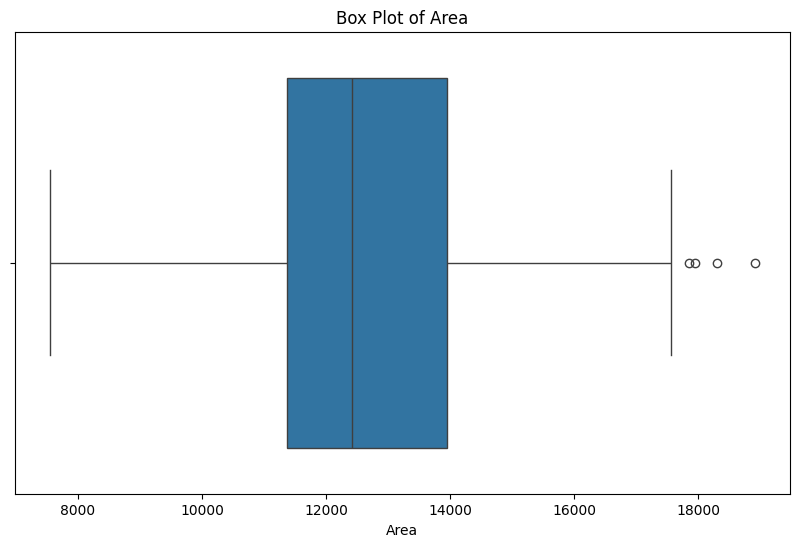

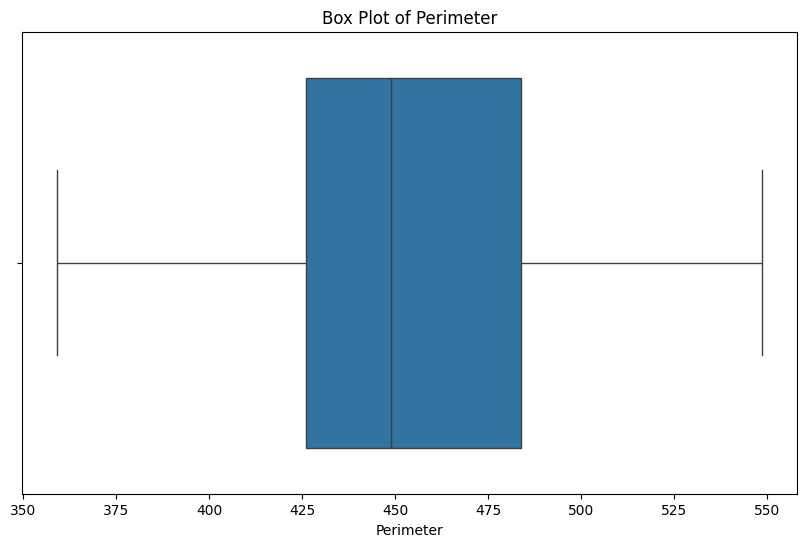

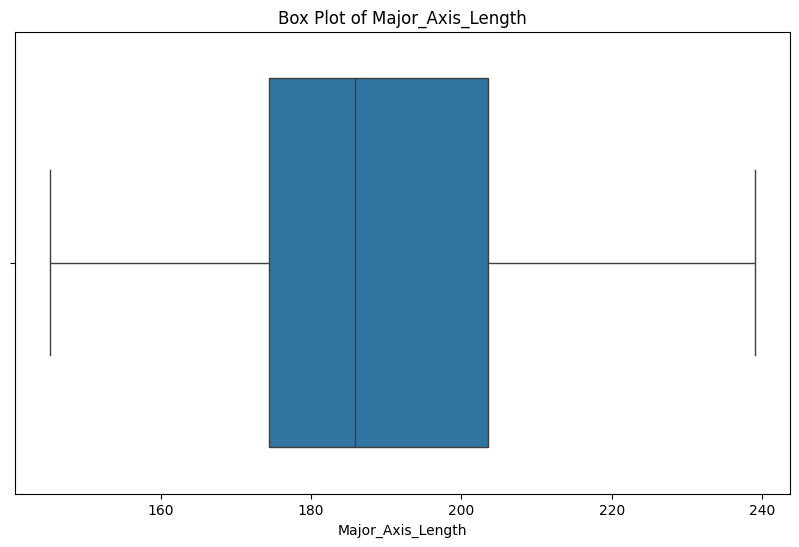

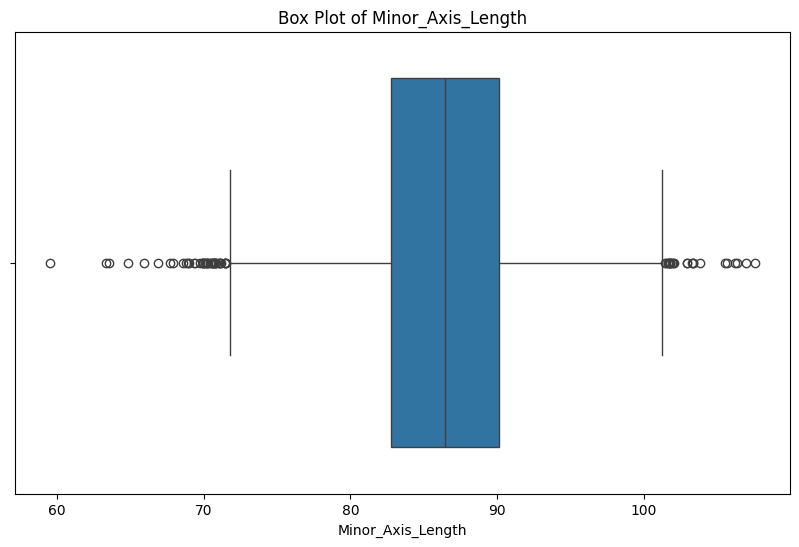

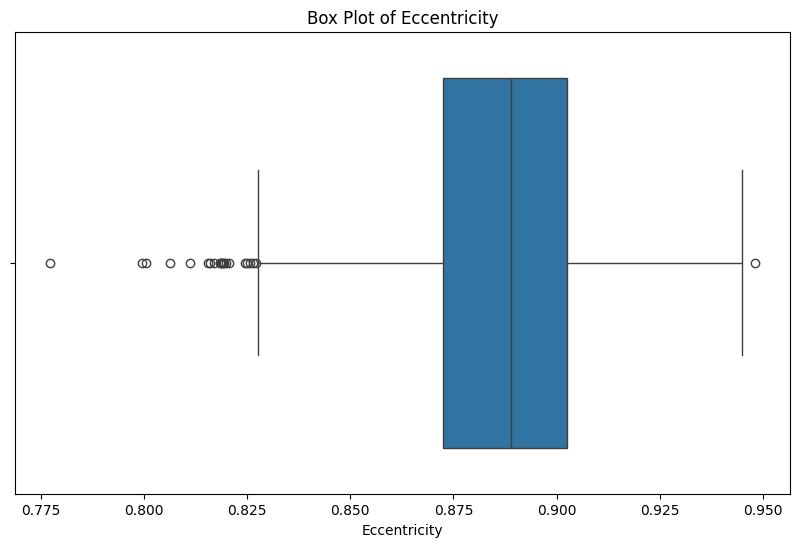

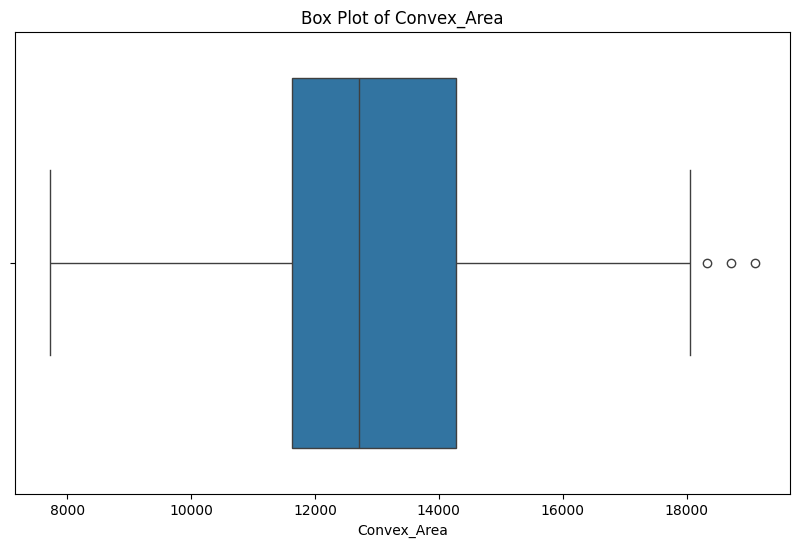

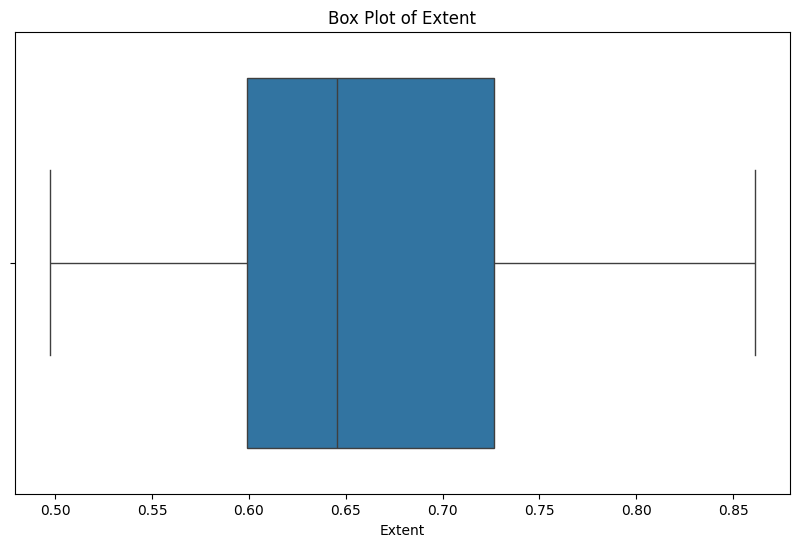

In [53]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [54]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [55]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [56]:
# Menentukan kolom yang ingin diganti outlier-nya (contoh: 'Area')
column_name = 'Area'

# Menghitung batas bawah dan batas atas untuk kolom tersebut
lower_bound = Q1[column_name] - 1.5 * IQR[column_name]
upper_bound = Q3[column_name] + 1.5 * IQR[column_name]

# Mengganti outlier dengan nilai batas terdekat (winsorizing)
df[column_name] = df[column_name].apply(
    lambda x: lower_bound if x < lower_bound else (upper_bound if x > upper_bound else x)
)

print(f"Outlier pada kolom '{column_name}' telah berhasil diganti dengan batas terdekat.")

Outlier pada kolom 'Area' telah berhasil diganti dengan batas terdekat.


In [57]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

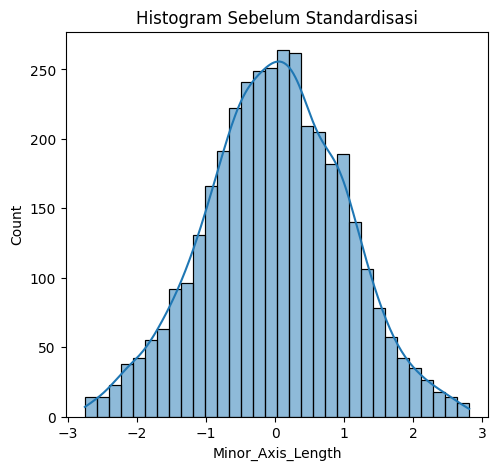

In [58]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

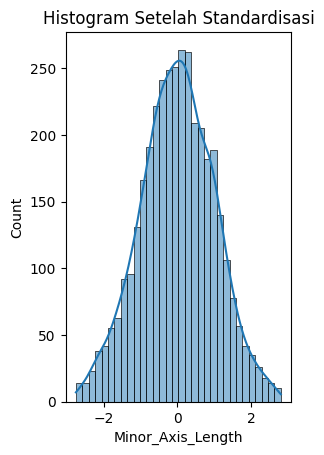

In [59]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [60]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Area, Perimeter, Major_Axis_Length, Minor_Axis_Length, Eccentricity, Convex_Area, Extent, Class]
Index: []


In [61]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
          Area  Perimeter  Major_Axis_Length  Minor_Axis_Length  Eccentricity  \
0     1.517541   2.027613           2.360076          -0.240224      2.091204   
1     1.174869   1.133866           0.987314           1.012903      0.418863   
2     1.161758   1.328548           1.455128           0.264733      1.253764   
3     0.292860   0.105776           0.253625           0.204336      0.241819   
4     1.193939   1.501335           1.318406           0.556277      0.982649   
...        ...        ...                ...                ...           ...   
3804 -0.109407  -0.081274           0.218997          -0.598711      0.750452   
3805 -0.741116  -1.108592          -1.068276          -0.115084     -1.135959   
3806 -0.631461  -0.950468          -1.228634           0.584620     -2.056654   
3807 -0.147548  -0.347101          -0.311246           0.082290     -0.293526   
3808 -1.670204  -1.782047          -1.605861          -1.539820     -0.

In [62]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

,Class
0,Cammeo
1,Cammeo
2,Cammeo
3,Cammeo
4,Cammeo
...,...
3804,Osmancik
3805,Osmancik
3806,Osmancik
3807,Osmancik


In [63]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class_Cammeo,Class_Osmancik
0,1.517541,2.027613,2.360076,-0.240224,2.091204,1.537243,-1.151452,True,False
1,1.174869,1.133866,0.987314,1.012903,0.418863,1.220718,-0.598461,True,False
2,1.161758,1.328548,1.455128,0.264733,1.253764,1.152185,0.413159,True,False
3,0.292860,0.105776,0.253625,0.204336,0.241819,0.231067,-0.270459,True,False
4,1.193939,1.501335,1.318406,0.556277,0.982649,1.331066,-0.200850,True,False
...,...,...,...,...,...,...,...,...,...
3804,-0.109407,-0.081274,0.218997,-0.598711,0.750452,-0.164445,0.745432,False,True
3805,-0.741116,-1.108592,-1.068276,-0.115084,-1.135959,-0.779492,0.253961,False,True
3806,-0.631461,-0.950468,-1.228634,0.584620,-2.056654,-0.619196,0.426415,False,True
3807,-0.147548,-0.347101,-0.311246,0.082290,-0.293526,-0.188838,-0.451542,False,True


In [64]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
 df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,1.517541,2.027613,2.360076,-0.240224,2.091204,1.537243,-1.151452,0
1,1.174869,1.133866,0.987314,1.012903,0.418863,1.220718,-0.598461,0
2,1.161758,1.328548,1.455128,0.264733,1.253764,1.152185,0.413159,0
3,0.292860,0.105776,0.253625,0.204336,0.241819,0.231067,-0.270459,0
4,1.193939,1.501335,1.318406,0.556277,0.982649,1.331066,-0.200850,0
...,...,...,...,...,...,...,...,...
3804,-0.109407,-0.081274,0.218997,-0.598711,0.750452,-0.164445,0.745432,1
3805,-0.741116,-1.108592,-1.068276,-0.115084,-1.135959,-0.779492,0.253961,1
3806,-0.631461,-0.950468,-1.228634,0.584620,-2.056654,-0.619196,0.426415,1
3807,-0.147548,-0.347101,-0.311246,0.082290,-0.293526,-0.188838,-0.451542,1


**Eda & Exda**

In [65]:
df_lencoder.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,1.517541,2.027613,2.360076,-0.240224,2.091204,1.537243,-1.151452,0
1,1.174869,1.133866,0.987314,1.012903,0.418863,1.220718,-0.598461,0
2,1.161758,1.328548,1.455128,0.264733,1.253764,1.152185,0.413159,0
3,0.292860,0.105776,0.253625,0.204336,0.241819,0.231067,-0.270459,0
4,1.193939,1.501335,1.318406,0.556277,0.982649,1.331066,-0.200850,0


In [66]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
 'Missing Values': missing_values,
 'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]  # Menampilkan kolom dengan missing values

,Missing Values,Percentage


In [ ]:
import matplotlib.pyplot as plt

# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4  # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menggunakan kolom yang benar-benar ada di dataset beras Anda
columns_to_plot = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [ ]:
import matplotlib.pyplot as plt

# Ganti 'SalePrice' dengan kolom target yang ada di dataframe Anda (misal: 'Class')
target_corr = df_lencoder.corr(numeric_only=True)['Class']

target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title('Correlation with Target Variable')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

**Data Splitting**

In [ ]:
import sklearn

In [ ]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['Class'])
y = df_lencoder['Class']

In [ ]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

### Pemrosesan dan Pembagian Dataset Kedua: Wine Quality

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Memuat dataset winequality dengan separator titik koma ';'
df_wine = pd.read_csv('/content/winequality.csv', sep=';')

# 2. Menangani missing values jika ada
df_wine = df_wine.fillna(df_wine.median(numeric_only=True))

# 3. Menentukan target (asumsi kolom target adalah 'quality')
target_col = 'quality' if 'quality' in df_wine.columns else df_wine.columns[-1]

# Memisahkan fitur dan target untuk Wine
X_wine = df_wine.drop(columns=[target_col])
y_wine = df_wine[target_col]

# 4. Standardisasi fitur numerik
scaler_wine = StandardScaler()
X_wine_scaled = scaler_wine.fit_transform(X_wine.select_dtypes(include=['number']))
X_wine = pd.DataFrame(X_wine_scaled, columns=X_wine.select_dtypes(include=['number']).columns)

# 5. Membagi menjadi data training dan testing untuk Wine
X_train_wine, X_test_wine, y_train_wine, y_test_wine = train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=1
)

print("Dataset Wine Quality berhasil dimuat dan dibagi!")
print(f"Ukuran data training Wine: {X_train_wine.shape}")
print(f"Ukuran data testing Wine: {X_test_wine.shape}")

In [ ]:
# menghitung panjang/jumlah data
print("Jumlah data: ", len(X))
# menghitung panjang/jumlah data pada X_train
print("Jumlah data latih: ", len(X_train))
# menghitung panjang/jumlah data pada X_test
print("Jumlah data test: ", len(X_test))

In [ ]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(X_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(X_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(X_train, y_train)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# 1. Pastikan pembagian data dijalankan ulang agar X_test tersedia
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# 2. Evaluasi pada model LARS (menggunakan X_test dengan huruf besar)
pred_lars = lars.predict(X_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# 3. Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}

# 4. Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

In [ ]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(X_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

In [ ]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(X_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

In [ ]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

In [ ]:
import pickle

# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)